# Workshop 3 — Part A, Steps 3 and 4: Feature Engineering and Regression Model

**Course:** ETL (G01) · **Program:** Data Engineering and Artificial Intelligence

This notebook continues the *offline process*:

```
data/processed/happiness_unified.csv      (output of eda.ipynb)
        |
        v
Step 3  Feature engineering (descriptive statistics, feature selection, preprocessing)
        |
        v
Step 4  Train + evaluate a regression model
        |
        v
models/model.pkl  (preprocessing + model in ONE scikit-learn Pipeline)
data/streaming/*.csv  (events that the Kafka producer will publish in Part B)
```

> The focus of the workshop is **pipeline integration, not model optimization**. The model is deliberately simple, and every choice is made so that the *same* preprocessing can be reproduced identically inside the streaming consumer.

In [1]:
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.width", 170)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_PATH = ROOT / "data" / "processed" / "happiness_unified.csv"
STREAMING_DIR = ROOT / "data" / "streaming"
MODELS_DIR = ROOT / "models"
STREAMING_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET = "happiness_score"
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]   # ORDER MATTERS: it is the model input order

df = pd.read_csv(PROCESSED_PATH)
print(df.shape)
df.head()

(782, 10)


,country,year,happiness_rank,happiness_score,gdp,family,health,freedom,generosity,corruption
0,Switzerland,2015,1,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,2015,2,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,2015,3,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,2015,4,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,2015,5,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957


## 1. Descriptive statistics and relationships between variables

In [2]:
display(df[[TARGET] + FEATURES].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.379,1.127,2.693,4.510,5.322,6.190,7.769
gdp,782.0,0.916,0.407,0.000,0.606,0.982,1.236,2.096
family,782.0,1.078,0.330,0.000,0.869,1.125,1.327,1.644
health,782.0,0.612,0.248,0.000,0.440,0.647,0.808,1.141
freedom,782.0,0.411,0.153,0.000,0.310,0.431,0.531,0.724
generosity,782.0,0.219,0.122,0.000,0.130,0.202,0.279,0.838
corruption,782.0,0.126,0.106,0.000,0.054,0.091,0.156,0.552


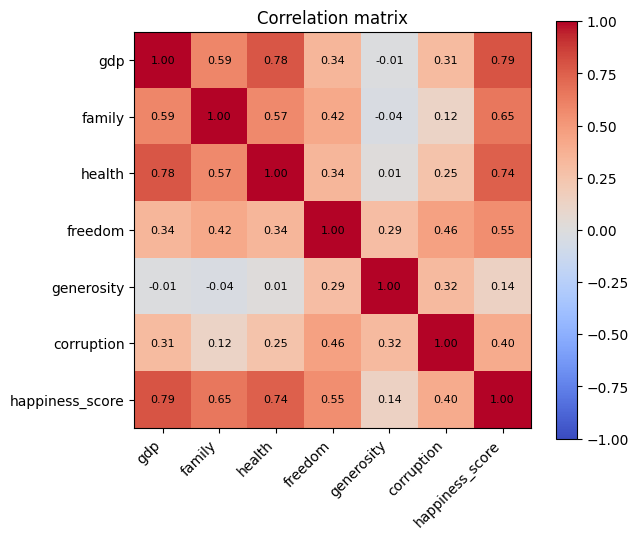

Correlation of each factor with the happiness score:
gdp           0.789
health        0.742
family        0.649
freedom       0.551
corruption    0.400
generosity    0.138


In [3]:
corr = df[FEATURES + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

print("Correlation of each factor with the happiness score:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

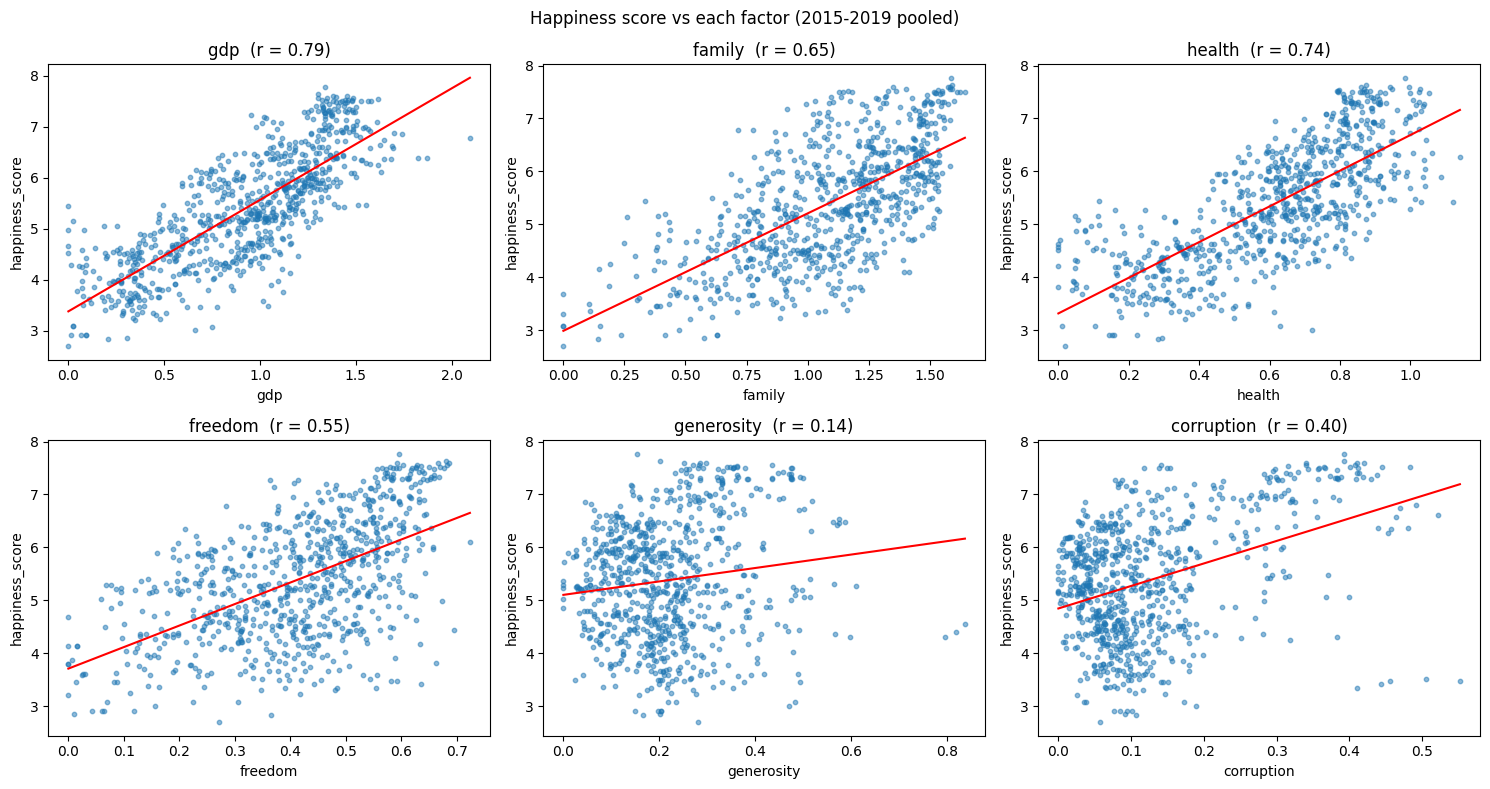

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    ax.scatter(df[col], df[TARGET], s=10, alpha=0.5)
    slope, intercept = np.polyfit(df[col], df[TARGET], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 50)
    ax.plot(xs, slope * xs + intercept, color="red")
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
    ax.set_title(f"{col}  (r = {df[col].corr(df[TARGET]):.2f})")
plt.suptitle("Happiness score vs each factor (2015-2019 pooled)")
plt.tight_layout()
plt.show()

**What the data says**

- `gdp`, `health` and `family` (social support) have the strongest linear relationship with the score, as expected. `freedom` is moderate, and `corruption` is weaker but positive. `generosity` has the weakest relationship.
- `gdp`, `health` and `family` are also correlated with each other (richer countries tend to have better health and social support). This is *multicollinearity*: it does not hurt prediction, but it means individual coefficients must be interpreted with care.
- The relationships look reasonably linear, which supports starting with a simple Linear Regression.

## 2. Feature selection

| Column | Decision | Justification |
|---|---|---|
| `gdp`, `family`, `health`, `freedom`, `generosity`, `corruption` | **Include** | Present in every year, numeric, on the same scale; they are the explanatory factors of the score; and they are exactly the numeric fields that the streaming **event contract** carries, so the consumer can always build the model input |
| `happiness_rank` | Exclude | **Target leakage**: it is computed from the score inside each year (correlation with the score about -0.99) |
| `Dystopia Residual`, `Standard Error`, confidence intervals, whiskers, `Region` | Exclude (already removed in `eda.ipynb`) | The first group is derived from the target (score = factors + dystopia residual) and the whole group is missing in some years; none of them exists in a streamed event |
| `country` | Exclude | An identifier with 164 values for 782 rows. A model would memorize countries instead of learning from the factors, and could not predict an unseen country. In streaming it is only the Kafka event key |
| `year` | Exclude | Used as the observation reference. The mean score is flat across years (5.35-5.41), so it adds no signal |
| `event_id` | Exclude | Identifier for traceability, not information |
| `actual_happiness_score` (streaming field) | **Never an input** | It is the target; in streaming it is only used afterwards to compute the prediction error |

**Categorical data:** after this selection every feature is numeric, so no encoding is required.

**Scaling:** a `StandardScaler` is included **inside the Pipeline**. It is not mandatory for Linear Regression, but it makes coefficients comparable and, more importantly, it is *learned preprocessing* (mean and standard deviation of the training data). Serializing it together with the model guarantees that the Kafka consumer applies exactly the same transformation.

In [5]:
LEAKY_OR_EXCLUDED = ["happiness_rank", "country", "year", "event_id", "actual_happiness_score", TARGET]
assert TARGET not in FEATURES
assert not set(FEATURES) & set(LEAKY_OR_EXCLUDED)
assert set(FEATURES) <= set(df.columns)
X, y, groups = df[FEATURES], df[TARGET], df["country"]
print("Model input (in this exact order):", FEATURES)

Model input (in this exact order): ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']


## 3. Train / test split (approximately 70 % / 30 %)

Each country appears in up to five years with very similar values. A plain random row split would put the same country in both sets and make the test score optimistic. The split is therefore **grouped by country**: a country is either entirely in training or entirely in testing. The proportion is approximately the 70 % / 30 % suggested by the workshop (exactly 69 % / 31 %, because whole countries are assigned to one side).

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

shared_countries = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert not shared_countries, "a country appears in both sets"

print(f"train: {len(train_idx)} rows ({len(train_idx) / len(df):.0%}) | test: {len(test_idx)} rows ({len(test_idx) / len(df):.0%})")
print(f"countries in train: {groups.iloc[train_idx].nunique()} | countries in test: {groups.iloc[test_idx].nunique()} | shared: {len(shared_countries)}")
print(f"mean score  train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

train: 542 rows (69%) | test: 240 rows (31%)
countries in train: 114 | countries in test: 50 | shared: 0
mean score  train: 5.386 | test: 5.364


## 4. Train and compare candidate models

The three models suggested by the workshop are wrapped in the same `Pipeline(StandardScaler -> model)`.

**Selection rule (decided before looking at the test set):** choose the lowest mean RMSE in a 5-fold cross-validation *on the training set only* (also grouped by country). The test set is used once, at the end, to report the final quality.

In [7]:
def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

candidates = {
    "Linear Regression": make_pipeline(LinearRegression()),
    "Decision Tree": make_pipeline(DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(RandomForestRegressor(n_estimators=200, max_depth=8, random_state=RANDOM_STATE)),
}

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

cv = GroupKFold(n_splits=5)
rows = []
for name, pipeline in candidates.items():
    cv_rmse = -cross_val_score(pipeline, X_train, y_train, groups=groups.iloc[train_idx],
                               cv=cv, scoring="neg_root_mean_squared_error")
    pipeline.fit(X_train, y_train)
    test = regression_metrics(y_test, pipeline.predict(X_test))
    rows.append({"model": name, "CV RMSE (train, 5 folds)": cv_rmse.mean(),
                 "test MAE": test["MAE"], "test RMSE": test["RMSE"], "test R2": test["R2"]})

comparison = pd.DataFrame(rows).set_index("model").round(3)
display(comparison)

best_name = comparison["CV RMSE (train, 5 folds)"].idxmin()
print("Selected by the rule (lowest CV RMSE):", best_name)

,"CV RMSE (train, 5 folds)",test MAE,test RMSE,test R2
model,,,,
Linear Regression,0.567,0.432,0.562,0.784
Decision Tree,0.668,0.556,0.711,0.654
Random Forest,0.589,0.473,0.604,0.751


Selected by the rule (lowest CV RMSE): Linear Regression


Linear Regression has the lowest cross-validated error, and it is also the simplest and most interpretable of the three, which fits the goal of the workshop. The more flexible models do not improve on it with only 6 smooth, correlated numeric features and around 540 training rows.

## 5. Evaluate the selected model

Model: Linear Regression
  MAE   = 0.432
  RMSE  = 0.562
  R2    = 0.784


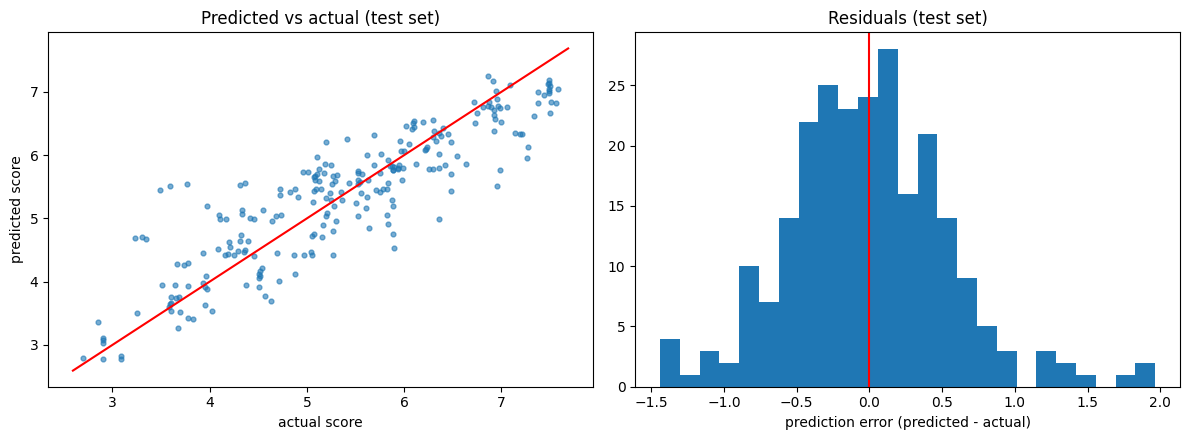

Mean absolute error of the test set by year:


,rows,MAE
year,,
2015,49,0.399
2016,48,0.493
2017,47,0.433
2018,47,0.429
2019,49,0.406


In [8]:
final_model = candidates[best_name]          # already fitted on the training set above
y_pred = final_model.predict(X_test)
final_metrics = regression_metrics(y_test, y_pred)

print(f"Model: {best_name}")
for metric, value in final_metrics.items():
    print(f"  {metric:<5} = {value:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, y_pred, s=12, alpha=0.6)
limits = [min(y_test.min(), y_pred.min()) - 0.1, max(y_test.max(), y_pred.max()) + 0.1]
axes[0].plot(limits, limits, color="red")
axes[0].set_xlabel("actual score")
axes[0].set_ylabel("predicted score")
axes[0].set_title("Predicted vs actual (test set)")

axes[1].hist(y_pred - y_test, bins=25)
axes[1].axvline(0, color="red")
axes[1].set_xlabel("prediction error (predicted - actual)")
axes[1].set_title("Residuals (test set)")
plt.tight_layout()
plt.show()

errors = (df.iloc[test_idx].assign(predicted=y_pred)
          .assign(abs_error=lambda d: (d["predicted"] - d[TARGET]).abs())
          .groupby("year")["abs_error"].agg(["count", "mean"]).round(3))
print("Mean absolute error of the test set by year:")
display(errors.rename(columns={"count": "rows", "mean": "MAE"}))

In [9]:
if best_name == "Linear Regression":
    coefficients = pd.Series(final_model.named_steps["model"].coef_, index=FEATURES).sort_values(ascending=False)
    print("Standardized coefficients (effect of +1 standard deviation on the predicted score):")
    print(coefficients.round(3).to_string())

Standardized coefficients (effect of +1 standard deviation on the predicted score):
gdp           0.454
freedom       0.241
family        0.238
health        0.204
corruption    0.073
generosity    0.063


**Reading the result**

- R² around 0.78 means that the six factors explain roughly four fifths of the variance of the score of countries *never seen during training*. A mean absolute error of about 0.43 points on a 0-10 scale is acceptable for a pipeline-integration workshop.
- The error is similar in every year (between 0.40 and 0.49), so the model is not tied to one specific survey wave.
- The goal is not to maximize accuracy: any further tuning would not change the architecture that Part B has to demonstrate.

## 6. Serialize the Pipeline (`models/model.pkl`)

The file contains the **whole Pipeline** (scaler + regressor), not just the regressor. A small JSON file next to it stores the contract between training and serving: the feature names **in the order the model expects them**, the target name and the quality metrics.

In [10]:
MODEL_PATH = MODELS_DIR / "model.pkl"
METADATA_PATH = MODELS_DIR / "model_metadata.json"

with open(MODEL_PATH, "wb") as file:
    pickle.dump(final_model, file)

metadata = {
    "model": best_name,
    "pipeline_steps": [name for name, _ in final_model.steps],
    "features": FEATURES,
    "target": TARGET,
    "random_state": RANDOM_STATE,
    "split": {"strategy": "GroupShuffleSplit by country", "test_size": 0.30,
              "train_rows": int(len(train_idx)), "test_rows": int(len(test_idx))},
    "cv_rmse_train": float(comparison.loc[best_name, "CV RMSE (train, 5 folds)"]),
    "test_metrics": {k: round(float(v), 4) for k, v in final_metrics.items()},
    "scikit_learn_version": sklearn.__version__,
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(json.dumps(metadata, indent=2))

{
  "model": "Linear Regression",
  "pipeline_steps": [
    "scaler",
    "model"
  ],
  "features": [
    "gdp",
    "family",
    "health",
    "freedom",
    "generosity",
    "corruption"
  ],
  "target": "happiness_score",
  "random_state": 42,
  "split": {
    "strategy": "GroupShuffleSplit by country",
    "test_size": 0.3,
    "train_rows": 542,
    "test_rows": 240
  },
  "cv_rmse_train": 0.567,
  "test_metrics": {
    "MAE": 0.4319,
    "RMSE": 0.5619,
    "R2": 0.7838
  },
  "scikit_learn_version": "1.8.0"
}


In [11]:
# Round trip: the file on disk must behave exactly like the model in memory.
with open(MODEL_PATH, "rb") as file:
    loaded = pickle.load(file)

assert list(loaded.feature_names_in_) == FEATURES, "feature order stored inside the Pipeline differs"
assert np.allclose(loaded.predict(X_test), final_model.predict(X_test))

# The same call the streaming consumer will make for one event: a one-row DataFrame in training order.
example_event = {"country": "Colombia", "year": 2019, "gdp": 1.2, "family": 0.8, "health": 0.9,
                 "freedom": 0.6, "generosity": 0.3, "corruption": 0.1}
prediction = loaded.predict(pd.DataFrame([example_event])[FEATURES])[0]
print(f"model.pkl loaded correctly. Prediction for the example event of the workshop: {prediction:.3f}")

model.pkl loaded correctly. Prediction for the example event of the workshop: 6.076


## 7. Prepare the events for the Kafka producer (`data/streaming/`)

The producer of Part B reads *prepared historical data record by record*. Each record becomes one event with exactly the fields of the event contract (`event_time` is added by the producer at the moment it emits the event).

- **`event_id`** is assigned from the position of the row in the unified dataset (`E001`, `E002`, ...), so every event can be traced back to its source row, and the same event always has the same id.
- **`stream_events.csv`** contains only the **test set** (countries never seen by the model). Streaming it gives an honest prediction error on the dashboard. This is the default source of the producer.
- **`stream_events_full.csv`** contains all rows and exists only to stress-test the pipeline (predictions on training rows are optimistic).

In [12]:
assert len(df) < 1000, "event_id format E### would need more digits"
events = df.copy()
events.insert(0, "event_id", [f"E{i:03d}" for i in range(1, len(events) + 1)])
events = events.rename(columns={TARGET: "actual_happiness_score"})

EVENT_COLUMNS = ["event_id", "country", "year"] + FEATURES + ["actual_happiness_score"]
events = events[EVENT_COLUMNS]

stream_test = events.iloc[test_idx].sort_values("event_id")
stream_full = events

stream_test.to_csv(STREAMING_DIR / "stream_events.csv", index=False)
stream_full.to_csv(STREAMING_DIR / "stream_events_full.csv", index=False)

assert stream_test["event_id"].is_unique and stream_full["event_id"].is_unique
assert set(stream_test["event_id"]) <= set(stream_full["event_id"])
print(f"stream_events.csv:      {len(stream_test)} events (test set)")
print(f"stream_events_full.csv: {len(stream_full)} events (all rows)")
stream_test.head()

stream_events.csv:      240 events (test set)
stream_events_full.csv: 782 events (all rows)


,event_id,country,year,gdp,family,health,freedom,generosity,corruption,actual_happiness_score
0,E001,Switzerland,2015,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,7.587
1,E002,Iceland,2015,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,7.561
6,E007,Netherlands,2015,1.32944,1.28017,0.89284,0.61576,0.47610,0.31814,7.378
10,E011,Israel,2015,1.22857,1.22393,0.91387,0.41319,0.33172,0.07785,7.278
15,E016,Brazil,2015,0.98124,1.23287,0.69702,0.49049,0.14574,0.17521,6.983


## 8. Artifacts produced by this notebook

| File | Used by |
|---|---|
| `models/model.pkl` | `kafka/consumer.py` (loads the Pipeline once at start-up) |
| `models/model_metadata.json` | `kafka/consumer.py` (feature order and the "missing features required by the model" check) |
| `data/streaming/stream_events.csv` | `kafka/producer.py` (default source) |
| `data/streaming/stream_events_full.csv` | `kafka/producer.py --source full` |

**Next:** Part B (Kafka producer and consumer) and Part C (PostgreSQL storage and dashboard).